<a href="https://colab.research.google.com/github/steventeng2022/ml-colab-1/blob/main/PyTorch_Advanced_Classification_L1_L2__10_21.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PyTorch 進階分類實作：Breast Cancer Dataset
### Overfitting · L1 / L2 Regularization · Dropout · Generalization

**延續 Titanic 二元分類課程**｜建議 3–4 小時｜難度：中階

本 Notebook 透過 30 維數值特徵建立 MLP，並比較 **Baseline、L1、L2、Dropout、L1+L2**。

**學習目標**
1. 正確區分 Train / Validation / Test，避免資料洩漏。
2. 探索高維特徵與相關性，理解特徵標準化。
3. 實作多層神經網路並觀察 Training/Validation loss。
4. 理解 L1 與 L2 的數學與 PyTorch 實作差異。
5. 使用 F1、Recall、ROC-AUC 及權重分布比較模型。


**擴充版：新增幾何圖、Penalty Gradient、PCA、Layer-wise Norm、λ 掃描、Soft Thresholding 與更多實驗解讀。**

## 0. 環境準備
需要 `torch`, `numpy`, `pandas`, `scikit-learn`, `matplotlib`, `seaborn`。若缺少套件，解除下方 pip 指令的註解後執行。

In [ ]:
# %pip install torch numpy pandas scikit-learn matplotlib seaborn
import copy, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, '| Device:', device)

PyTorch: 2.11.0+cpu | Device: cpu


## 1. 資料理解與 EDA

資料集：569 筆觀測、30 個連續特徵、2 個類別。原始 `target` 編碼為 **0 = malignant（惡性）**、**1 = benign（良性）**。

**思考**：Accuracy 很高時，為什麼仍應查看 Recall？注意 Recall 必須先明確定義「哪個類別是 positive」。本課將**惡性設為 positive（1）**，方便討論漏判惡性的風險。

In [ ]:
raw = load_breast_cancer(as_frame=True)
X_df = raw.data.copy()
y = (raw.target == 0).astype(int)  # 1 = 惡性, 0 = 良性
print('X shape:', X_df.shape)
print('Label counts (1=malignant):')
print(y.value_counts().sort_index())
display(X_df.head())
print('Missing values:', X_df.isna().sum().sum())

X shape: (569, 30)
Label counts (1=malignant):
target
0    357
1    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Missing values: 0


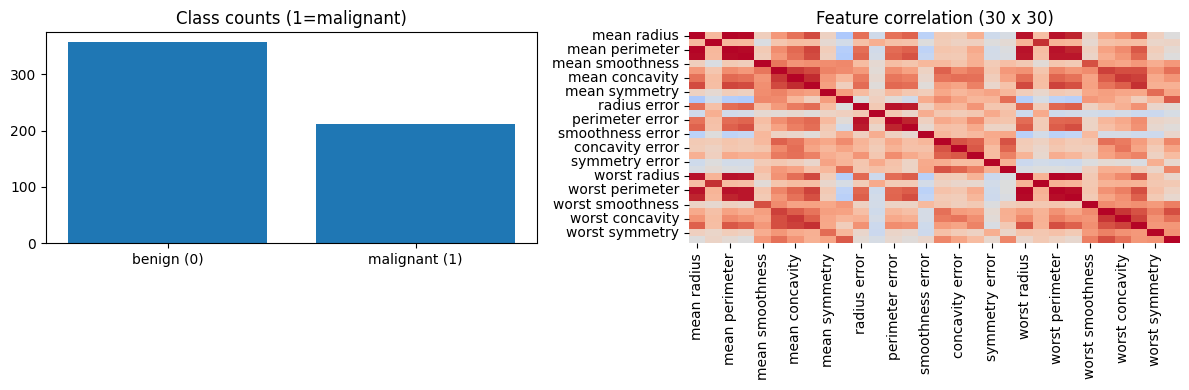

Highly correlated feature pairs (> 0.9, absolute): 21


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].bar(['benign (0)', 'malignant (1)'], [int((y==0).sum()), int((y==1).sum())]); axes[0].set_title('Class counts (1=malignant)')
correlation = X_df.corr()
sns.heatmap(correlation, cmap='coolwarm', center=0, ax=axes[1], cbar=False)
axes[1].set_title('Feature correlation (30 x 30)')
plt.tight_layout(); plt.show()
print('Highly correlated feature pairs (> 0.9, absolute):', int((np.triu(abs(correlation.values),1)>0.9).sum()))

## 2. 切分資料與標準化（避免 Data Leakage）

先把 **Test（20%）** 留到最後。其餘資料再分 Train / Validation。為了讓過擬合更容易觀察，預設僅使用約 **120 筆訓練資料**；可以自行調大 `TRAIN_SIZE` 觀察差異。

`StandardScaler.fit()` **只允許在 Train 上**執行，Val/Test 僅能 `transform()`；`stratify` 維持各子集類別比例。

In [ ]:
X_pool, X_test, y_pool, y_test = train_test_split(
    X_df, y, test_size=0.20, random_state=SEED, stratify=y)
X_train_all, X_val, y_train_all, y_val = train_test_split(
    X_pool, y_pool, test_size=0.25, random_state=SEED, stratify=y_pool)
TRAIN_SIZE = 120  # 小樣本實驗：試著改成 300
X_train, _, y_train, _ = train_test_split(
    X_train_all, y_train_all, train_size=TRAIN_SIZE, random_state=SEED, stratify=y_train_all)
scaler = StandardScaler()
Xtr = scaler.fit_transform(X_train).astype(np.float32)
Xva = scaler.transform(X_val).astype(np.float32)
Xte = scaler.transform(X_test).astype(np.float32)
ytr = np.asarray(y_train, dtype=np.float32).reshape(-1,1)
yva = np.asarray(y_val, dtype=np.float32).reshape(-1,1)
yte = np.asarray(y_test, dtype=np.float32).reshape(-1,1)
print('Train/Val/Test:', len(Xtr), len(Xva), len(Xte))
print('Positive (malignant) ratios:', *[round(float(z.mean()),3) for z in (ytr,yva,yte)])
train_ds = TensorDataset(torch.from_numpy(Xtr),torch.from_numpy(ytr))
val_x = torch.from_numpy(Xva).to(device); val_y = torch.from_numpy(yva).to(device)
test_x = torch.from_numpy(Xte).to(device); test_y = torch.from_numpy(yte).to(device)

Train/Val/Test: 120 114 114
Positive (malignant) ratios: 0.375 0.377 0.368


## 3. 多層感知器（MLP）與 Binary Cross Entropy

本課直接輸出 **logits**，使用 `BCEWithLogitsLoss`（內部處理 sigmoid，通常比先 sigmoid 再 BCELoss 穩定）。預測時再用 `torch.sigmoid(logits)` 得到機率。

模型：`30 → 128 → 64 → 32 → 1`，ReLU 激活；可選擇 Dropout。

$$\mathcal L_{\mathrm{BCE}}=-\frac1N\sum_{i=1}^{N}[y_i\log p_i+(1-y_i)\log(1-p_i)]$$

In [ ]:
class CancerMLP(nn.Module):
    def __init__(self, in_features=30, dropout=0.0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features,128), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(128,64), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(64,32), nn.ReLU(), nn.Linear(32,1)
        )
    def forward(self,x):
        return self.net(x)

model = CancerMLP().to(device)
print(model)
print('Trainable parameters:',sum(p.numel() for p in model.parameters() if p.requires_grad))

CancerMLP(
  (net): Sequential(
    (0): Linear(in_features=30, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.0, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.0, inplace=False)
    (6): Linear(in_features=64, out_features=32, bias=True)
    (7): ReLU()
    (8): Linear(in_features=32, out_features=1, bias=True)
  )
)
Trainable parameters: 14337


## 正規化

• L1 正規化（Lasso）：
	• 作法：在損失函數中加入參數的絕對值總和。
	• 特性：會讓許多不重要的特徵權重直接變為 0，產生「稀疏性（Sparseness）」，具有自動選擇特徵的效果。

• L2 正規化（Ridge）：
	• 作法：在損失函數中加入參數的平方總和。
	• 特性：不會將權重變為 0，而是將所有權重均勻縮小，讓模型更穩定、抗雜訊能力更好。



3. 數學原理（直觀理解）

在訓練模型時，原本我們只希望「預測誤差（Loss）」越小越好。加入正規化後，目標變成了：
\(\text{新的目標}=\text{預測誤差}+\lambda \times \text{模型複雜度}\)
• \(\lambda \)（Lambda） 是我們控制處罰力道的按鈕。如果 \(\lambda \) 很大，代表處罰很重，權重會被壓得很低。
• L1 複雜度計算：\(\sum \vert{}w_i\vert{}\) （幾何上像是一個正方形 / 菱形的邊界，最優解很容易碰在頂點上，也就是某個坐標軸為 0 的地方，因此產生稀疏性）。
• L2 複雜度計算：\(\sum w_i^2\) （幾何上像是一個圓形的邊界，最優解會被均勻向圓心拉近，但很難剛好卡在軸上，所以權重只會變小，不會變 0）。


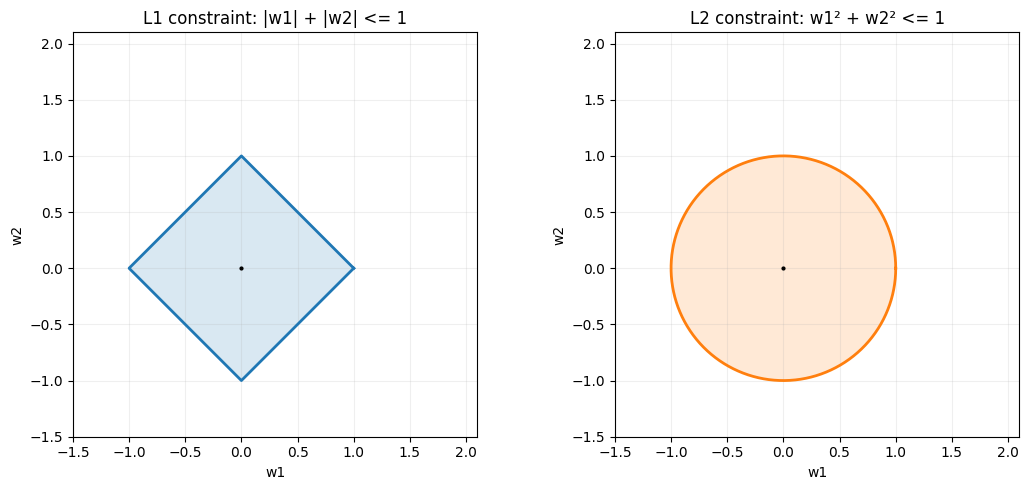

In [ ]:
from matplotlib.patches import Polygon, Circle, Ellipse
fig,axes=plt.subplots(1,2,figsize=(11,5))
for ax,kind in zip(axes,['L1 constraint: |w1| + |w2| <= 1','L2 constraint: w1² + w2² <= 1']):
    if kind.startswith('L1'):
        ax.add_patch(Polygon([(1,0),(0,1),(-1,0),(0,-1)],closed=True,alpha=.17,color='tab:blue'))
        ax.plot([1,0,-1,0,1],[0,1,0,-1,0],color='tab:blue',lw=2)
    else:
        ax.add_patch(Circle((0,0),1,alpha=.17,color='tab:orange'))
        t=np.linspace(0,2*np.pi,400);ax.plot(np.cos(t),np.sin(t),color='tab:orange',lw=2)
    ax.plot([0], [0], 'k.',markersize=4)
    ax.set(xlim=(-1.5,2.1),ylim=(-1.5,2.1),xlabel='w1',ylabel='w2',title=kind)
    ax.set_aspect('equal');ax.grid(alpha=.2)
plt.tight_layout();plt.show()

### 圖 2：L1 與 L2 的幾何直覺

將「能接受的模型權重」畫成限制區域：L1 的等值線在二維呈 **菱形**，L2 呈 **圓形**。當資料損失的等高線向原點靠近時，更容易在 L1 的尖角（某權重為 0）處接觸到限制區。**這是示意圖，不是這份真實神經網路的 loss landscape。**

In [ ]:
# 圖 1：懲罰函數以及導數（避開 0 的 L1 不可微點）
w_axis = np.linspace(-2.5,2.5,601)
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(w_axis,np.abs(w_axis),label='L1 |w|',lw=2)
ax[0].plot(w_axis,w_axis**2,label='L2 w²',lw=2)
ax[0].set(title='Penalty shape',xlabel='Weight',ylabel='Penalty')
ax[1].plot(w_axis,np.sign(w_axis),label='L1 subgradient (0 chosen as 0)',lw=2)
ax[1].plot(w_axis,2*w_axis,label='L2 derivative',lw=2)
ax[1].set(title='Penalty gradient',xlabel='Weight',ylabel='Gradient')
for a in ax:a.axhline(0,color='gray',lw=.8);a.axvline(0,color='gray',lw=.8);a.grid(alpha=.25);a.legend()
plt.tight_layout();plt.show()

## 4A. 為什麼 Regularization 有用？（深入理解）

### 4A-1 從 Empirical Risk 到 Regularized Risk

給定特徵 $x_i$ 和標籤 $y_i$，神經網路學習權重 $W$，希望最小化訓練資料上的 BCE：

$$\mathcal L_{\mathrm{BCE}} = -\frac1N\sum_{i=1}^{N}\left[y_i\log p_i +(1-y_i)\log(1-p_i)\right]$$

但訓練資料只有一部分世界的樣貌。若模型容量很高，可能記住訓練樣本中的偶然雜訊，造成**訓練誤差小、驗證誤差大**。於是加入對參數大小的偏好：

$$\boxed{\mathcal J(W)=\mathcal L_{\mathrm{BCE}}(W) + \lambda R(W)}$$

- $\lambda=0$：沒有額外限制；$\lambda$ 大：偏好較小或較稀疏的權重。
- **L1 / Lasso 型**：$R_1(W)=\sum_j |w_j|$；**L2 / Ridge 型**：$R_2(W)=\sum_j w_j^2$。
- 本 Notebook 的 `regularization_penalty` 用 **mean** 而不是 sum；因此 `l1=0.2` 不可直接與另一份用 sum 的程式相比。
- 為簡化概念，通常只懲罰 `weight`，不懲罰 `bias`；正規化不是「強制權重全部愈小愈好」，而是權衡擬合與複雜度。

### 4A-2 推導梯度：為何 L1 產生稀疏性？

$$\frac{\partial}{\partial w}\lambda|w|=\lambda\,\mathrm{sign}(w)\quad(w\ne0)$$
$$\frac{\partial}{\partial w}\lambda w^2=2\lambda w$$

**L1** 對非零權重的推力大小約固定，不會因為靠近 0 就消失；在 0 處不可微，可用次梯度。**L2** 的推力與權重大小成正比，接近 0 時越弱。這是 L1 容易得到稀疏權重、L2 通常把權重平滑縮小的原因之一。注意：一般使用 Adam + L1 penalty **不保證得到精確的 0**。

### 4A-3 兩個常見誤區

1. **L2 不是 Dropout**：前者懲罰權重大小，後者在訓練期間隨機遮蔽 activation。
2. **L2 penalty 不等於任何 optimizer 的 `weight_decay`**：純 SGD 可寫出等價關係；對 Adam，耦合的 L2 梯度與 AdamW 的 decoupled weight decay 不同。

## 4. Regularization 原理

原始 loss：$\mathcal L_{\mathrm{BCE}}$。加入懲罰後：

$$\mathcal L = \mathcal L_{\mathrm{BCE}} + \lambda_1\sum_{w\in W}|w| + \lambda_2\sum_{w\in W} w^2$$

- **L1**：鼓勵稀疏權重，部分權重可能非常接近 0。梯度（非零點）額外增加 $\lambda_1\,\mathrm{sign}(w)$；在 0 使用次梯度概念。
- **L2**：偏好較小、較平滑的權重，梯度額外增加 $2\lambda_2 w$。
- **Dropout**：訓練時隨機將部分 activation 設為 0，推論時自動停用。

**容易混淆的重點**：
- `torch.optim.SGD(weight_decay=λ)` 的 weight decay，在普通 SGD 下相當於在 loss 加上 **$(λ/2)\sum w^2$**（若正規化施加在相同參數上）。
- `AdamW(weight_decay=λ)` 採 **decoupled weight decay**，並**不等同**直接將 $λ\sum w^2$ 加入 Adam 的 loss。
- 本教材為清楚比較 **L1 與 L2 penalty 的數學定義**，兩者都採 **手動加到 loss**、optimizer 固定使用 Adam 且 `weight_decay=0`；另提供 AdamW 延伸實驗。
- 這裡只懲罰 `weight` 矩陣，不懲罰 bias；懲罰採「所有權重元素的平均」避免超參數對參數數量過度敏感。因而 $\lambda$ 值與使用 sum 定義的教材**不可直接比較**。

In [ ]:
def regularization_penalty(model, l1=0.0, l2=0.0):
    weights = torch.cat([p.reshape(-1) for name,p in model.named_parameters() if name.endswith('weight')])
    return l1 * weights.abs().mean() + l2 * weights.square().mean()

# 小例子：同樣 magnitude 的兩組權重，對 L1/L2 penalty 的影響
w = torch.tensor([0.0, 0.5, -2.0])
print('w:',w.tolist())
print('L1 sum:',w.abs().sum().item(),'| L2 sum of squares:',w.square().sum().item())

values = np.linspace(-2,2,300)
plt.figure(figsize=(8,3.5)); plt.plot(values,abs(values),label='L1: |w|'); plt.plot(values,values**2,label='L2: w²')
plt.title('L1 vs L2 penalty for one weight'); plt.xlabel('Weight');plt.ylabel('Penalty');plt.legend();plt.grid(alpha=.2);plt.show()

## 5. 訓練工具
使用固定隨機種子，讓模型比較更公平。每個 epoch 記錄 **Train BCE / Validation BCE**（繪圖比較不含 penalty，以相同標準看泛化），另外記錄 training objective（含 penalty）。

> 為了公平觀察學習曲線，下面預設 **不使用 Early Stopping**。在正式應用時，可以用 Validation 選最佳 checkpoint，再於 Test 評估一次。

In [ ]:
def train_model(l1=0.0, l2=0.0, dropout=0.0, lr=1e-3, epochs=180, batch_size=32, seed=SEED,
                optimizer_name='adam', weight_decay=0.0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    net = CancerMLP(Xtr.shape[1], dropout).to(device)
    if optimizer_name == 'adam':
        optimizer = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=weight_decay)
    elif optimizer_name == 'adamw':
        optimizer = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        raise ValueError('optimizer_name must be adam or adamw')
    criterion = nn.BCEWithLogitsLoss()
    loader = DataLoader(train_ds,batch_size=batch_size,shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    history = {'train_bce':[],'train_objective':[],'val_bce':[]}
    best = {'loss':float('inf'),'epoch':0,'state':None}
    for epoch in range(epochs):
        net.train(); total_bce=0.; total_obj=0.
        for xb,yb in loader:
            xb,yb=xb.to(device),yb.to(device)
            optimizer.zero_grad()
            bce=criterion(net(xb),yb)
            objective=bce+regularization_penalty(net,l1=l1,l2=l2)
            objective.backward(); optimizer.step()
            total_bce += bce.item()*len(xb)
            total_obj += objective.item()*len(xb)
        net.eval()
        with torch.no_grad():
            val_loss=criterion(net(val_x),val_y).item()
        history['train_bce'].append(total_bce/len(train_ds))
        history['train_objective'].append(total_obj/len(train_ds))
        history['val_bce'].append(val_loss)
        if val_loss < best['loss']:
            best={'loss':val_loss,'epoch':epoch+1,'state':copy.deepcopy(net.state_dict())}
    # 以 val BCE 取得 best checkpoint；不偷看 test
    net.load_state_dict(best['state'])
    return net, history, best['epoch']

def evaluate_model(net, x, y):
    net.eval()
    with torch.no_grad():
        probs=torch.sigmoid(net(x)).cpu().numpy().ravel()
    truth=y.cpu().numpy().astype(int).ravel()
    pred=(probs>=0.5).astype(int)
    return {'Accuracy':accuracy_score(truth,pred),
            'Precision':precision_score(truth,pred,zero_division=0),
            'Recall':recall_score(truth,pred,zero_division=0),
            'F1':f1_score(truth,pred,zero_division=0),
            'ROC-AUC':roc_auc_score(truth,probs)},probs,pred

def plot_loss(histories):
    plt.figure(figsize=(11,5))
    for name,h in histories.items():
        plt.plot(h['val_bce'],label=f'{name} Val',linewidth=2)
        plt.plot(h['train_bce'],linestyle='--',alpha=.65,label=f'{name} Train')
    plt.xlabel('Epoch');plt.ylabel('BCE loss (without penalty)')
    plt.title('Train vs Validation loss');plt.legend(ncol=2);plt.grid(alpha=.2);plt.show()

In [ ]:
from sklearn.decomposition import PCA
pca=PCA(n_components=2).fit(Xtr)
proj_train=pca.transform(Xtr);proj_val=pca.transform(Xva)
fig,axs=plt.subplots(1,2,figsize=(12,4))
for ax,pts,labels,title in [(axs[0],proj_train,ytr.ravel(),'Train'),(axs[1],proj_val,yva.ravel(),'Validation')]:
    for cls in [0,1]:
        m=(labels==cls);ax.scatter(pts[m,0],pts[m,1],alpha=.7,s=26,label=('Benign' if cls==0 else 'Malignant'))
    ax.set(title=title+' — PCA feature projection',xlabel='PC1',ylabel='PC2');ax.grid(alpha=.2);ax.legend()
plt.suptitle(f'Explained variance by PC1 & PC2: {pca.explained_variance_ratio_.sum():.1%}')
plt.tight_layout();plt.show()

## 5A. 視覺化：決策邊界（2D 投影概念）

30 維神經網路無法直接畫出完整 decision boundary。因此這裡採用 **PCA 2D 投影**，顯示資料在前兩個主成分的分布，幫助理解類別可分性。這是資料投影，**不是 30 維模型的真實決策邊界**，避免誤導。

## 6. 實驗 A：Baseline 及 Overfitting

觀察 Train Loss 下降，但 Validation Loss 不一定持續下降。因資料切分、亂數與訓練環境，**不保證每次都會出現很明顯的過擬合**。

In [ ]:
baseline, baseline_hist, baseline_best = train_model()
plot_loss({'Baseline':baseline_hist})
print('Best validation epoch:',baseline_best)
print('Val metrics:',evaluate_model(baseline,val_x,val_y)[0])

## 7. 實驗 B：L1 / L2 / Dropout 比較

所有模型使用相同資料切分、learning rate、epochs 與 initial seed。正規化係數為**教學用起始值**，不代表這是最佳設定；稍後可以透過 Validation 調整。

In [ ]:
settings = {
    'Baseline': dict(),
    'L1': dict(l1=0.2),
    'L2': dict(l2=0.5),
    'Dropout': dict(dropout=0.3),
    'L1 + L2': dict(l1=0.1,l2=0.25),
}
models, histories, val_rows = {}, {}, []
for name, kw in settings.items():
    m, h, ep = train_model(**kw)
    models[name]=m; histories[name]=h
    metrics=evaluate_model(m,val_x,val_y)[0]
    val_rows.append({'Model':name,'Best Epoch':ep, 'Val BCE':min(h['val_bce']),**metrics})
val_results=pd.DataFrame(val_rows).set_index('Model').sort_values('F1',ascending=False)
display(val_results.round(4))

In [ ]:
plot_loss(histories)

In [ ]:
# 圖 5：Validation 指標（不是 Test），指標不同可能導致最佳模型不同
cols=['Accuracy','Precision','Recall','F1','ROC-AUC']
ax=val_results[cols].sort_index().plot.bar(figsize=(12,4.5),ylim=(0,1.05),rot=0)
ax.set(title='Validation metrics by regularization strategy',ylabel='Score')
ax.legend(bbox_to_anchor=(1.01,1),loc='upper left');ax.grid(axis='y',alpha=.2)
plt.tight_layout();plt.show()

In [ ]:
# 圖 4：各模型分開看，避免五條重疊造成難以判讀
fig,axes=plt.subplots(2,3,figsize=(15,8))
for ax,(name,h) in zip(axes.flat,histories.items()):
    ax.plot(h['train_bce'],label='Train BCE',lw=1.8)
    ax.plot(h['val_bce'],label='Val BCE',lw=1.8)
    best_ep=int(np.argmin(h['val_bce']))+1
    ax.axvline(best_ep,color='gray',linestyle=':',label=f'Best epoch: {best_ep}')
    ax.set(title=name,xlabel='Epoch',ylabel='BCE');ax.legend(fontsize=8);ax.grid(alpha=.2)
for ax in list(axes.flat)[len(histories):]:ax.axis('off')
plt.tight_layout();plt.show()

## 7A. 視覺化比較：哪些模型「看起來」過擬合？

**如何讀圖：**
- Train BCE 持續下降且 Val BCE 開始回升 → 可能在 overfit。
- 訓練曲線高於未加正規化的模型，**不一定是壞事**，因為限制會提高 training error。
- 以 Validation 最佳 epoch 作比較，不拿 Test 選模型。
- **注意**：使用 Dropout 時 train loss 由 train mode 計算，包含隨機遮蔽；Validation 在 eval mode，數值不能直接當成完全相同條件下的 loss。

### 7.1 權重分布與稀疏性

L1 通常更容易使權重**接近** 0，但在 Adam + L1 的實作中不保證產生大量**精確** 0。這裡用 `abs(weight) < 1e-3` 定義「近零」；此門檻是視覺化示例，不等於真正做完特徵選擇。

In [ ]:
def flatten_weights(m):
    return torch.cat([p.detach().cpu().flatten() for name,p in m.named_parameters() if name.endswith('weight')]).numpy()
fig,axes=plt.subplots(1,2,figsize=(12,4))
weight_rows=[]
for name,m in models.items():
    w=flatten_weights(m)
    axes[0].hist(w,bins=70,alpha=.35,label=name,density=True)
    weight_rows.append({'Model':name,'Mean |w|':np.mean(abs(w)),'Near-zero fraction':np.mean(abs(w)<1e-3)})
axes[0].set_xlim(-.6,.6); axes[0].set_title('Weight distribution');axes[0].legend(fontsize=8)
wf=pd.DataFrame(weight_rows).set_index('Model')
wf['Near-zero fraction'].plot.bar(ax=axes[1]);axes[1].set_title('Fraction of |w| < 1e-3');axes[1].set_ylim(0,1)
plt.tight_layout();plt.show()
display(wf.round(4))

In [ ]:
# 圖 9：一維解析解（不是神經網路訓練）
a=np.linspace(-2,2,401)
fig,ax=plt.subplots(figsize=(8,4))
for lam in [0.2,0.8]:
    ax.plot(a,np.sign(a)*np.maximum(np.abs(a)-lam,0),label=f'L1, lambda={lam}')
    ax.plot(a,a/(1+2*lam),'--',label=f'L2, lambda={lam}')
ax.plot(a,a,':',color='gray',label='No penalty')
ax.set(xlabel='Unregularized optimum a',ylabel='Regularized optimum w*',title='L1 soft-threshold vs L2 shrinkage')
ax.legend();ax.grid(alpha=.2);plt.show()

### 7D. 用合成權重示範：Soft Thresholding 與 L1 精確零

考慮特別簡單的最佳化問題：$\frac12 (w-a)^2 + \lambda |w|$，L1 的解析解是 **soft thresholding**：

$$w^*=\mathrm{sign}(a)\max(|a|-\lambda,0).$$

相同的 squared-error + L2 問題 $\frac12(w-a)^2+\lambda w^2$，解是 $w^*=a/(1+2\lambda)$。這說明 L1 **可以**把小係數精確壓到 0，L2 則平滑縮小；**此解析結果不能直接套到非凸神經網路 + Adam**。

In [ ]:
# 圖 8：Regularization strength vs validation performance and weight magnitude
lambdas=[0.0,0.01,0.05,0.2,0.5,1.0]
sweep_epochs=90
sweep_rows=[]
for reg in ['L1','L2']:
    for lam in lambdas:
        kw={'l1':lam} if reg=='L1' else {'l2':lam}
        m,h,best_epoch=train_model(**kw,epochs=sweep_epochs)
        w=flatten_weights(m)
        sweep_rows.append({'Method':reg,'lambda':lam,'Val BCE':min(h['val_bce']),
                           'Mean |w|':np.abs(w).mean(),'Near-zero <1e-3':(np.abs(w)<1e-3).mean(),
                           'Best Epoch':best_epoch})
sweep_df=pd.DataFrame(sweep_rows)
fig,ax=plt.subplots(1,3,figsize=(15,4))
for method,g in sweep_df.groupby('Method'):
    for a,metric in zip(ax,['Val BCE','Mean |w|','Near-zero <1e-3']):
        a.plot(g['lambda'],g[metric],marker='o',label=method)
for a,metric in zip(ax,['Val BCE','Mean |w|','Near-zero <1e-3']):
    a.set(xlabel='lambda',ylabel=metric,title=metric+' vs lambda');a.grid(alpha=.25);a.legend()
plt.tight_layout();plt.show()
display(sweep_df.round(5))

## 7C. 重要補充：正規化強度 $\lambda$ 的影響

以下用**同一種 L1 或 L2 定義（mean penalty）**，比較多個 $\lambda$。觀察最佳 Validation BCE、Weight magnitude 與 Near-zero ratio。這是教學用 **Validation 掃描**，不是正式調整 Test 的程序。

> 此實驗會再訓練多個模型，在 CPU 上可能比較耗時。把 `sweep_epochs` 降低可以加快課堂演示，但實驗精度也會改變。

In [ ]:
# 圖 6：不同 near-zero thresholds 的敏感度
thresholds=np.logspace(-5,-1,35)
plt.figure(figsize=(9,4.5))
for name,m in models.items():
    w=np.abs(flatten_weights(m));plt.semilogx(thresholds,[(w<t).mean() for t in thresholds],label=name,lw=2)
plt.xlabel('Near-zero threshold');plt.ylabel('Fraction of |weight| below threshold')
plt.title('Sparsity depends on the chosen threshold');plt.grid(alpha=.25);plt.legend();plt.show()

# 圖 7：不同 Linear layer 權重的平均絕對值
rows=[]
for name,m in models.items():
    for layer,p in m.named_parameters():
        if layer.endswith('weight'):
            rows.append({'Model':name,'Layer':layer,'Mean absolute weight':p.detach().abs().mean().item()})
norm_df=pd.DataFrame(rows)
pivot=norm_df.pivot(index='Layer',columns='Model',values='Mean absolute weight')
pivot.plot(kind='bar',figsize=(11,4.5),rot=0)
plt.title('Mean absolute weights by layer');plt.ylabel('Mean |weight|');plt.grid(axis='y',alpha=.2);plt.tight_layout();plt.show()

## 7B. 更多視覺化：權重稀疏程度與 Layer-wise Norm

`|weight| < 10^-3` 是**人為設定的近零門檻**，不是數學上的精確零；不同門檻可能得到不同的結論。不同層的參數數量也不同，因此對比 Layer-wise norm 時應同時觀察 mean absolute weight。

## 8. Test Set：最終評估

**重要**：模型或超參數應以 Validation 決定，Test 只在決策完成後評估一次。本課以下使用 Validation F1 決定最終模型，然後只評估該模型的 Test 表現。

Recall = TP / (TP + FN)，此處 positive = malignant。

In [ ]:
best_name=val_results.index[0]
final_model=models[best_name]
test_metrics,test_probs,test_pred=evaluate_model(final_model,test_x,test_y)
print('Selected on validation F1:',best_name)
print('Test metrics:')
display(pd.Series(test_metrics).round(4).to_frame('Value'))
print(classification_report(yte.astype(int).ravel(),test_pred,target_names=['benign','malignant'],zero_division=0))
cm=confusion_matrix(yte.astype(int).ravel(),test_pred)
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=['benign','malignant'],yticklabels=['benign','malignant'])
plt.xlabel('Predicted');plt.ylabel('True');plt.title('Test confusion matrix');plt.show()

## 9. 延伸：L2 Penalty、SGD Weight Decay、AdamW 的關係

對 plain SGD，`weight_decay=wd` 與手動加 `(wd/2) * sum(weight**2)` 的梯度等價（**條件是對相同參數施加懲罰**）。但在 AdamW 中，decoupled weight decay 與「將平方和加進 loss」不是同一運算。以下用小張量驗證 SGD 的梯度：

In [ ]:
w = torch.tensor([1.0,-2.0],requires_grad=True)
wd=0.1
loss=(w**2).sum() + (wd/2)*(w**2).sum()
loss.backward()
print('Gradient of base + SGD-style L2 penalty:',w.grad.tolist())
print('Expected gradient = 2*w + wd*w:',(2*w.detach()+wd*w.detach()).tolist())

### Optional：AdamW 比較（使用 Validation，不能拿 Test 調參）

In [ ]:
adamw_model, adamw_hist, adamw_best = train_model(optimizer_name='adamw', weight_decay=0.05)
print('AdamW validation:',evaluate_model(adamw_model,val_x,val_y)[0])
plot_loss({'Baseline':baseline_hist,'AdamW':adamw_hist})

In [ ]:
# 圖 10：同一模型 training BCE 與加上 penalty 的 training objective
fig,axs=plt.subplots(1,2,figsize=(11,4))
for a,name in zip(axs,['L1','L2']):
    h=histories[name]
    a.plot(h['train_bce'],label='Train BCE')
    a.plot(h['train_objective'],label='Train objective (BCE + penalty)')
    a.plot(h['val_bce'],label='Validation BCE')
    a.set(title=name+' loss definitions',xlabel='Epoch',ylabel='Loss');a.grid(alpha=.2);a.legend(fontsize=8)
plt.tight_layout();plt.show()

## 9A. 訓練時的總目標與 Validation BCE 不是同一件事

**Training objective = Training BCE + penalty**。比較不同超參數的驗證品質，應看相同定義的 **Validation BCE**（或者事先決定的 F1 / Recall）。不應直接拿加了不同 penalty 的 objective 數值比較模型好壞。

## 10. 課堂練習：TODO + Hints

### Exercise 1 — 觀察 Train Size 對 Overfitting 的影響
**TODO**：把 `TRAIN_SIZE` 從 120 改成 300，重新執行第 2–7 節。比較 Train/Val Loss 間距與 Validation F1。

**Hint**：資料量增加不一定讓 train accuracy 更高，但可能讓 validation 更穩定。

### Exercise 2 — L1/L2 Hyperparameter Sweep
**TODO**：用 Validation 測 `l1 ∈ {0, 0.05, 0.2, 0.5}`、`l2 ∈ {0, 0.1, 0.5, 1.0}`。不要使用 Test 來挑選。

**Hint**：呼叫 `train_model(l1=..., l2=...)`，使用 `evaluate_model(m, val_x, val_y)`。

### Exercise 3 — 手寫正規化函數
**TODO**：自行寫 `my_l1(model)` 與 `my_l2(model)`，回傳每個 weight 的平均絕對值、平方值（不含 bias）。

**Hint**：`model.named_parameters()`、`name.endswith('weight')`、`torch.cat`。

### Exercise 4 — Class Imbalance
**TODO**：將訓練資料刻意做不平衡抽樣，觀察 Accuracy 與 Recall 的落差（測試集保持原樣）。

**Hint**：只修改 training subset，不能改 validation/test。可以試 `BCEWithLogitsLoss(pos_weight=...)`，`pos_weight` 只能依 Train 資料估算。

### Exercise 5 — Reflection
請回答：
1. 為什麼 Validation Loss 最低的 epoch 不一定是最後一個 epoch？
2. L1 的近零權重是否等於刪除輸入特徵？為什麼？
3. 在這個資料集中，惡性 Recall 與 Accuracy 哪個更值得注意？
4. 為什麼 `AdamW(weight_decay=0.1)` 不能直接稱為「loss + 0.1 × L2 平方和」？

In [ ]:
# TODO Exercise 2: 完成 Validation hyperparameter search
l1_values = [0.0, 0.05, 0.2, 0.5]
l2_values = [0.0, 0.1, 0.5, 1.0]
search_rows = []
# TODO: 使用雙層 for 迴圈，呼叫 train_model 與 evaluate_model
# for l1_value in l1_values:
#     for l2_value in l2_values:
#         ...
#         search_rows.append({'l1':..., 'l2':..., 'Val F1':...})
# display(pd.DataFrame(search_rows).sort_values('Val F1',ascending=False).head())

## 11. Takeaways
- **分類不只是 Accuracy**：必須先定義 positive class，並檢視 Recall / F1 / ROC-AUC。
- **Train vs Validation loss**：理解模型擬合程度與泛化的落差。
- **L1**：促使參數稀疏；**L2**：抑制過大的參數；**Dropout**：在訓練中加入隨機失活。
- **Weight Decay ≠ 在所有 optimizer 都一樣的 L2 penalty**，尤其要區分 Adam 和 AdamW。
- **只用 Validation 做選擇，Test 留到最後**。本資料量少，單次切分具有變異，延伸可使用多組 seeds 或 stratified cross-validation。

**下一堂可銜接**：多類別分類（`CrossEntropyLoss` + softmax）、不平衡資料、Feature Selection 與模型可解釋性。